In [1]:
!pip install --no-index --find-links=/kaggle/input/torch-geometric /kaggle/input/torch-geometric/tg/torch_geometric-2.7.0-py3-none-any.whl
!rm -rf /kaggle/working/*

Looking in links: /kaggle/input/torch-geometric
Processing /kaggle/input/torch-geometric/tg/torch_geometric-2.7.0-py3-none-any.whl


In [2]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np
from torch_geometric.data import Data
import torch_geometric.transforms as TG
from tqdm import tqdm
import sys
import copy
import math


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [3]:
def random_rotation_matrix(batch_size=1):
    u1, u2, u3 = torch.rand(3, batch_size)
    q0 = torch.sqrt(1 - u1) * torch.sin(2 * np.pi * u2)
    q1 = torch.sqrt(1 - u1) * torch.cos(2 * np.pi * u2)
    q2 = torch.sqrt(u1) * torch.sin(2 * np.pi * u3)
    q3 = torch.sqrt(u1) * torch.cos(2 * np.pi * u3)
    R = torch.zeros(batch_size, 3, 3)
    R[:, 0, 0] = 1 - 2 * (q2**2 + q3**2)
    R[:, 0, 1] = 2 * (q1 * q2 - q0 * q3)
    R[:, 0, 2] = 2 * (q1 * q3 + q0 * q2)
    R[:, 1, 0] = 2 * (q1 * q2 + q0 * q3)
    R[:, 1, 1] = 1 - 2 * (q1**2 + q3**2)
    R[:, 1, 2] = 2 * (q2 * q3 - q0 * q1)
    R[:, 2, 0] = 2 * (q1 * q3 - q0 * q2)
    R[:, 2, 1] = 2 * (q2 * q3 + q0 * q1)
    R[:, 2, 2] = 1 - 2 * (q1**2 + q2**2)
    return R



In [4]:
R = random_rotation_matrix(batch_size=1).squeeze()  # shape (3,3)

# Print the rotation matrix
print("Rotation matrix R:")
print(R)
print()

# Check orthogonality: R @ R.T should be identity
ortho_check = R.T @ R
print("R @ R.T (should be identity):")
print(ortho_check)
print()

# Check determinant
det = torch.det(R)
print(f"Determinant: {det.item()}")
print()

# Assert both conditions
is_orthogonal = torch.allclose(R @ R.T, torch.eye(3), atol=1e-6)
is_det_one = torch.allclose(det, torch.tensor(1.0), atol=1e-6)

print(f"Is orthogonal? {is_orthogonal}")
print(f"Is det = 1? {is_det_one}")

assert is_orthogonal and is_det_one, "Matrix is not in SO(3)"

Rotation matrix R:
tensor([[-0.4134,  0.8326,  0.3686],
        [ 0.5467, -0.0967,  0.8317],
        [ 0.7282,  0.5454, -0.4152]])

R @ R.T (should be identity):
tensor([[ 1.0000e+00,  8.4524e-08,  3.6577e-08],
        [ 8.4524e-08,  1.0000e+00, -6.1583e-09],
        [ 3.6577e-08, -6.1583e-09,  1.0000e+00]])

Determinant: 0.9999998807907104

Is orthogonal? True
Is det = 1? True


In [5]:
download_path = "/kaggle/input/shapenet/02691156"
processed_dir = "output_dir"
MAX_SAMPLES = None 


def custom_read_obj(file_path):
    pos = []
    faces = []
    
    with open(file_path, 'r') as f:
        for line in f:
            components = line.strip().split()
            if not components:
                continue
            if components[0] == 'v':
                pos.append([float(x) for x in components[1:4]])
            elif components[0] == 'f':
                indices = [int(c.split('/')[0]) - 1 for c in components[1:]]
                for i in range(1, len(indices) - 1):
                    faces.append([indices[0], indices[i], indices[i + 1]])

    if not pos:
        return Data(pos=torch.empty((0, 3)), face=torch.empty((2, 0)))

    pos_tensor = torch.tensor(pos, dtype=torch.float)
    
    if faces:
        face_tensor = torch.tensor(faces, dtype=torch.long).t().contiguous()
    else:
        face_tensor = torch.empty((3, 0), dtype=torch.long)
    
    return Data(pos=pos_tensor, face=face_tensor)


def process_shapenet_mesh(data_folder, output_folder=None, num_points=2048, max_samples=float('inf')):
    sampler = TG.SamplePoints(num=num_points, include_normals=False)
    processed_count = 0
    errors = []
    ret = []
    
    print(f"Scanning {data_folder} for models (max {max_samples} samples)...")
    
    for root, _, files in os.walk(data_folder):
        if processed_count >= max_samples:
            break
        for file in files:
            if processed_count >= max_samples:
                break
            if file == "model_normalized.obj":
                file_path = os.path.join(root, file)
                path_parts = os.path.normpath(file_path).split(os.sep)
                
                try:
                    if 'models' in path_parts:
                        models_index = path_parts.index('models')
                        model_id = path_parts[models_index - 1]
                        category_id = path_parts[models_index - 2]
                    else:
                        continue
                    
                    if output_folder:
                        check_save_cat_dir = os.path.join(output_folder, category_id)
                        check_output_path = os.path.join(check_save_cat_dir, f"{model_id}.pt")
                        if os.path.exists(check_output_path):
                            continue

                    data = custom_read_obj(file_path)
                    if data.pos.size(0) == 0:
                        continue

                    data = sampler(data)
                    
                    if output_folder:
                        save_cat_dir = os.path.join(output_folder, category_id)
                        os.makedirs(save_cat_dir, exist_ok=True)
                        output_path = os.path.join(save_cat_dir, f"{model_id}.pt")
                        torch.save(data.pos, output_path)

                    ret.append(data)
                    processed_count += 1
                    if processed_count % 100 == 0:
                        print(f"Processed {processed_count} meshes...")
                        
                except Exception as e:
                    errors.append((file_path, str(e)))
                    
    print(f"Finished. Total processed: {processed_count}")
    if errors:
        print(f"Encountered {len(errors)} errors.")
    return ret


class ShapeNetPointCloudDataset(Dataset):
    def __init__(self, data_dir, num_points=2048, max_samples=None):
        self.data_dir = data_dir
        self.num_points = num_points
        self.samples = []
        self.cat_to_idx = {}
        
        categories = sorted([d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))])
        for idx, cat in enumerate(categories):
            self.cat_to_idx[cat] = idx
            cat_path = os.path.join(data_dir, cat)
            for file in os.listdir(cat_path):
                if file.endswith(".pt"):
                    self.samples.append((os.path.join(cat_path, file), cat))
                    if max_samples and len(self.samples) >= max_samples:
                        break
            if max_samples and len(self.samples) >= max_samples:
                break

    def __len__(self):
        return len(self.samples)

    def _sample_points(self, pc):
        n = pc.size(0)
        if n == self.num_points:
            return pc
        if n > self.num_points:
            idx = torch.randperm(n)[:self.num_points]
            return pc[idx]
        pad_idx = torch.randint(0, n, (self.num_points - n,))
        return torch.cat([pc, pc[pad_idx]], dim=0)

    def __getitem__(self, idx):
        file_path, cat = self.samples[idx]
        pc = torch.load(file_path, weights_only=True)
        pc = self._sample_points(pc)
        pc = pc - pc.mean(dim=0, keepdim=True)
        label = self.cat_to_idx[cat]
        R = random_rotation_matrix(1)[0]
        pc_rotated = pc @ R
        return pc_rotated, label, R


if not os.path.exists(processed_dir) or not any(
    file.endswith(".pt")
    for _, _, files in os.walk(processed_dir)
    for file in files
):
    process_shapenet_mesh(download_path, output_folder=processed_dir, num_points=2048, max_samples=MAX_SAMPLES or float('inf'))

print(f"Processed dataset ready at: {processed_dir}")

Scanning /kaggle/input/shapenet/02691156 for models (max inf samples)...
Processed 100 meshes...
Processed 200 meshes...
Processed 300 meshes...
Processed 400 meshes...
Processed 500 meshes...
Processed 600 meshes...
Processed 700 meshes...
Processed 800 meshes...
Processed 900 meshes...
Processed 1000 meshes...
Processed 1100 meshes...
Processed 1200 meshes...
Processed 1300 meshes...
Processed 1400 meshes...
Processed 1500 meshes...
Processed 1600 meshes...
Processed 1700 meshes...
Processed 1800 meshes...
Processed 1900 meshes...
Processed 2000 meshes...
Processed 2100 meshes...
Processed 2200 meshes...
Processed 2300 meshes...
Processed 2400 meshes...
Processed 2500 meshes...
Processed 2600 meshes...
Processed 2700 meshes...
Processed 2800 meshes...
Processed 2900 meshes...
Processed 3000 meshes...
Processed 3100 meshes...
Processed 3200 meshes...
Processed 3300 meshes...
Processed 3400 meshes...
Processed 3500 meshes...
Processed 3600 meshes...
Processed 3700 meshes...
Processed 3

In [6]:
EPS = 1e-6

class VNLinear(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(VNLinear, self).__init__()
        self.map_to_feat = nn.Linear(in_channels, out_channels, bias=False)
    
    def forward(self, x):
        '''
        x: point features of shape [B, N_feat, 3, N_samples, ...]
        '''
        x_out = self.map_to_feat(x.transpose(1,-1)).transpose(1,-1)
        return x_out


class VNLeakyReLU(nn.Module):
    def __init__(self, in_channels, share_nonlinearity=False, negative_slope=0.2):
        super(VNLeakyReLU, self).__init__()
        if share_nonlinearity == True:
            self.map_to_dir = nn.Linear(in_channels, 1, bias=False)
        else:
            self.map_to_dir = nn.Linear(in_channels, in_channels, bias=False)
        self.negative_slope = negative_slope
    
    def forward(self, x):
        '''
        x: point features of shape [B, N_feat, 3, N_samples, ...]
        '''
        d = self.map_to_dir(x.transpose(1,-1)).transpose(1,-1)
        dotprod = (x*d).sum(2, keepdim=True)
        mask = (dotprod >= 0).float()
        d_norm_sq = (d*d).sum(2, keepdim=True)
        x_out = self.negative_slope * x + (1-self.negative_slope) * (mask*x + (1-mask)*(x-(dotprod/(d_norm_sq+EPS))*d))
        return x_out


class VNBatchNorm(nn.Module):
    def __init__(self, num_features, dim):
        super(VNBatchNorm, self).__init__()
        self.dim = dim
        if dim == 3 or dim == 4:
            self.bn = nn.BatchNorm1d(num_features)
        elif dim == 5:
            self.bn = nn.BatchNorm2d(num_features)
    
    def forward(self, x):
        '''
        x: point features of shape [B, N_feat, 3, N_samples, ...]
        '''
        norm = torch.norm(x, dim=2) + EPS
        norm_bn = self.bn(norm)
        norm = norm.unsqueeze(2)
        norm_bn = norm_bn.unsqueeze(2)
        x = x / norm * norm_bn
        return x


class VNLinearLeakyReLU(nn.Module):
    def __init__(self, in_channels, out_channels, dim=5, share_nonlinearity=False, negative_slope=0.2):
        super(VNLinearLeakyReLU, self).__init__()
        self.dim = dim
        self.negative_slope = negative_slope
        
        self.map_to_feat = nn.Linear(in_channels, out_channels, bias=False)
        self.batchnorm = VNBatchNorm(out_channels, dim=dim)
        
        if share_nonlinearity == True:
            self.map_to_dir = nn.Linear(in_channels, 1, bias=False)
        else:
            self.map_to_dir = nn.Linear(in_channels, out_channels, bias=False)
    
    def forward(self, x):
        '''
        x: point features of shape [B, N_feat, 3, N_samples, ...]
        '''
        # Linear
        p = self.map_to_feat(x.transpose(1,-1)).transpose(1,-1)
        # BatchNorm
        # p = self.batchnorm(p)
        # LeakyReLU
        d = self.map_to_dir(x.transpose(1,-1)).transpose(1,-1)
        dotprod = (p*d).sum(2, keepdims=True)
        mask = (dotprod >= 0).float()
        d_norm_sq = (d*d).sum(2, keepdims=True)
        x_out = self.negative_slope * p + (1-self.negative_slope) * (mask*p + (1-mask)*(p-(dotprod/(d_norm_sq+EPS))*d))
        return x_out
    


class VNMaxPool(nn.Module):
    def __init__(self, in_channels):
        super(VNMaxPool, self).__init__()
        self.map_to_dir = nn.Linear(in_channels, in_channels, bias=False)
    
    def forward(self, x):
        '''
        x: point features of shape [B, N_feat, 3, N_samples, ...]
        '''
        d = self.map_to_dir(x.transpose(1,-1)).transpose(1,-1)
        dotprod = (x*d).sum(2, keepdims=True)
        idx = dotprod.max(dim=-1, keepdim=False)[1]
        index_tuple = torch.meshgrid([torch.arange(j) for j in x.size()[:-1]]) + (idx,)
        x_max = x[index_tuple]
        return x_max


def mean_pool(x, dim=-1, keepdim=False):
    return x.mean(dim=dim, keepdim=keepdim)


In [7]:
class VNEncoder(nn.Module):
    """SO(3)-equivariant encoder ϕ: R^{N×3} → R^{C×3×N}
    Uses VNN layers (Deng et al., 2021) with [B, C, 3, N] tensor layout.
    Section 4.2: ϕ(PR) = ϕ(P)R (equivariant by construction).
    """
    def __init__(self, in_channels=1, hidden_channels=64, out_channels=128):
        super().__init__()
        self.conv1 = VNLinearLeakyReLU(in_channels, hidden_channels, dim=4)
        self.conv2 = VNLinearLeakyReLU(hidden_channels, hidden_channels, dim=4)
        self.conv3 = VNLinearLeakyReLU(hidden_channels, out_channels, dim=4)
    
    def forward(self, x):
        # x: [B, N, 3] → [B, 1, 3, N]
        x = x.permute(0, 2, 1).unsqueeze(1)  # [B, 1, 3, N]
        x = self.conv1(x)   # [B, hidden, 3, N]
        x = self.conv2(x)   # [B, hidden, 3, N]
        x = self.conv3(x)   # [B, out, 3, N]
        return x  # [B, C, 3, N]


class VNInvariantLayer(nn.Module):
    """Produces SO(3)-equivariant frame V: R^{C×3×N} → R^{3×3×N}
    Section 4.3, Eq. 4: Used to compute invariant features via ϕ(PR)(VR)^T = ϕ(P)V^T.
    Inspired by VNN invariant layer (Deng et al., 2021, Eq. 14).
    """
    def __init__(self, in_channels):
        super().__init__()
        self.vn1 = VNLinearLeakyReLU(in_channels, in_channels // 2, dim=4)
        self.vn2 = VNLinearLeakyReLU(in_channels // 2, in_channels // 4, dim=4)
        self.vn_lin = VNLinear(in_channels // 4, 3)
    
    def forward(self, x):
        # x: [B, C, 3, N]
        x = self.vn1(x)      # [B, C//2, 3, N]
        x = self.vn2(x)      # [B, C//4, 3, N]
        V = self.vn_lin(x)   # [B, 3, 3, N]
        return V


class RotationPredictor(nn.Module):
    """SO(3)-equivariant rotation predictor ψ: R^{C×3×N} → SO(3)
    Section 4.2: Reduces channels from C to 2 basis vectors,
    then orthonormalises via Gram-Schmidt to produce ψ(ϕ(PR)) ∈ SO(3).
    Equivariance: h(PR) = ψ(ϕ(PR)) = ψ(ϕ(P))R = h(P)R  (Eq. 3)
    """
    def __init__(self, in_channels):
        super().__init__()
        self.vn_lin = VNLinear(in_channels, 2)

    def forward(self, x):
        # ── Input ──────────────────────────────────────────────────────────
        # x: [B, C, 3, N]   (SO(3)-equivariant feature from VNEncoder)
        #   B = batch, C = 128 channels, 3 = spatial dim, N = num points

        # ── Step 1: channel reduction C → 2 ────────────────────────────────
        # VNLinear applies a weight matrix W ∈ R^{2×C} in the channel dim
        # only, leaving the 3D spatial and N dims untouched.
        # Equivariance: VNLinear(x R) = VNLinear(x) R  ✓
        basis = self.vn_lin(x)          # [B, C, 3, N] → [B, 2, 3, N]

        # ── Step 2: global mean pool over points ────────────────────────────
        # Summation / mean over N is permutation-invariant and linear,
        # so equivariance is preserved: mean(x_i R) = mean(x_i) R  ✓
        basis = basis.mean(dim=-1)      # [B, 2, 3, N] → [B, 2, 3]

        # ── Step 3: split into two candidate basis vectors ──────────────────
        # Each is an SO(3)-equivariant 3D vector in R^3.
        v1 = basis[:, 0, :]             # [B, 3]
        v2 = basis[:, 1, :]             # [B, 3]

        # ── Step 4: Gram-Schmidt orthonormalisation → SO(3) ─────────────────
        # Paper Sec 4.2: "orthonormalising the vectors by Gram-Schmidt"
        #
        # e1 = v1 / ||v1||
        # Equivariance: normalize(v1 R) = normalize(v1) R  ✓
        e1 = F.normalize(v1, dim=-1)                         # [B, 3]

        # Project v2 onto the plane ⊥ to e1:
        #   e2_proj = v2 - (v2 · e1) e1
        # (v2 · e1) is SO(3)-INVARIANT (dot product), so it acts as a
        # scalar coefficient — the direction e2_proj transforms as v2 R  ✓
        dot = (v2 * e1).sum(dim=-1, keepdim=True)            # [B, 1]  invariant
        e2_proj = v2 - dot * e1                              # [B, 3]  equivariant

        # FIX: eps belongs INSIDE F.normalize, NOT added to the vector.
        # Adding 1e-6 to the vector (old code) shifts all 3 components,
        # destroying the orthogonality guarantee: e2 would no longer be
        # exactly perpendicular to e1. F.normalize(·, eps=1e-6) divides by
        # max(||e2_proj||, 1e-6) which is numerically safe without any
        # geometric corruption.
        e2 = F.normalize(e2_proj, dim=-1, eps=1e-6)          # [B, 3]  equivariant

        # e3 = e1 × e2  →  right-handed frame, guarantees det(R) = +1
        # cross(u R, v R) = det(R) · (u × v) R = (u × v) R  for R ∈ SO(3)  ✓
        e3 = torch.cross(e1, e2, dim=-1)                     # [B, 3]  equivariant

        # ── Step 5: assemble rotation matrix ────────────────────────────────
        # Stack AS COLUMNS: R[:,j] = e_{j+1}
        # When input rotates by R_test each column rotates: ej(PR) = ej(P) R_test
        # So R_mat(PR) = R_mat(P) @ R_test  →  h(PR) = h(P) R  ✓  (Eq. 3)
        R = torch.stack([e1, e2, e3], dim=1)                # [B, 3, 3]
        return R

class OrientationHypothesizer(nn.Module):
    """SO(3)-equivariant orientation hypothesizer h = ψ ∘ ϕ (Section 4.2)
    Eq. 3: h(PR) = ψ(ϕ(PR)) = ψ(ϕ(P))R = h(P)R
    Also produces equivariant features ϕ(PR) and frame V for the residual predictor.
    """
    def __init__(self, hidden_channels=64, out_channels=128):
        super().__init__()
        self.encoder = VNEncoder(1, hidden_channels, out_channels)
        self.rotation_predictor = RotationPredictor(out_channels)
        self.inv_layer = VNInvariantLayer(out_channels)
    
    def forward(self, x):
        # x: [B, N, 3]
        equiv_feat = self.encoder(x)              # [B, C, 3, N]
        R_hyp = self.rotation_predictor(equiv_feat)  # [B, 3, 3]
        V = self.inv_layer(equiv_feat)             # [B, 3, 3, N]
        return R_hyp, equiv_feat, V

In [8]:
class InvariantFeatureExtractor(nn.Module):
    """Extracts SO(3)-invariant features from equivariant features.
    Section 4.3, Eq. 4: ϕ(PR)(VR)^T = ϕ(P)RR^T V^T = ϕ(P)V^T (invariant).
    Based on VNN invariant layer principle (Deng et al., 2021, Eq. 13).
    """
    def __init__(self, in_channels, frame_channels=3):
        super().__init__()
        self.in_channels = in_channels
        self.frame_channels = frame_channels
    
    def forward(self, phi_feat, V_feat):
        # phi_feat: [B, C, 3, N] - SO(3)-equivariant feature ϕ(PR)
        # V_feat:   [B, 3, 3, N] - SO(3)-equivariant frame VR
        # Computes ϕ(PR)(VR)^T per point: result[b,c,d,n] = Σ_i phi[b,c,i,n] * V[b,d,i,n]
        inv_feat = torch.einsum('bcin,bdin->bcdn', phi_feat, V_feat)  # [B, C, 3, N]
        B, C, D, N = inv_feat.shape
        # Reshape to [B, N, C*3] for Point Transformer input
        return inv_feat.permute(0, 3, 1, 2).reshape(B, N, C * D)


class PointTransformerLayer(nn.Module):
    """Point Transformer layer (Zhao et al., 2021, Eq. 3).
    yi = Σ_{xj ∈ X(i)} ρ(γ(φ(xi) - ψ(xj) + δ)) ⊙ (α(xj) + δ)
    where δ = θ(pi - pj), θ and γ are MLPs with 2 linear layers and 1 ReLU,
    φ, ψ, α are linear projections, ρ is softmax, X(i) is kNN of point i.
    """
    def __init__(self, in_dim, out_dim=None, num_neighbors=16):
        super().__init__()
        out_dim = out_dim or in_dim
        self.num_neighbors = num_neighbors
        self.phi = nn.Linear(in_dim, out_dim)
        self.psi = nn.Linear(in_dim, out_dim)
        self.alpha = nn.Linear(in_dim, out_dim)
        # Position encoding θ: MLP with 2 linear + 1 ReLU (Eq. 4 in Zhao et al.)
        self.pos_enc = nn.Sequential(
            nn.Linear(3, out_dim),
            nn.ReLU(),
            nn.Linear(out_dim, out_dim)
        )
        # Attention mapping γ: MLP with 2 linear + 1 ReLU
        self.gamma = nn.Sequential(
            nn.Linear(out_dim, out_dim),
            nn.ReLU(),
            nn.Linear(out_dim, out_dim)
        )
        self.out_dim = out_dim
    
    def forward(self, x, pos):
        # x: [B, N, D], pos: [B, N, 3]
        B, N, D = x.shape
        k = min(self.num_neighbors, N)
        
        # kNN graph construction
        with torch.no_grad():
            dists = torch.cdist(pos, pos)                      # [B, N, N]
            _, knn_idx = dists.topk(k, dim=-1, largest=False)  # [B, N, k]
        
        batch_idx = torch.arange(B, device=x.device).view(B, 1, 1).expand(B, N, k)
        
        x_neighbors = x[batch_idx, knn_idx]            # [B, N, k, D]
        pos_neighbors = pos[batch_idx, knn_idx]         # [B, N, k, 3]
        
        # Feature transformations: φ(xi), ψ(xj), α(xj)
        phi_x = self.phi(x).unsqueeze(2)                # [B, N, 1, out_dim]
        psi_x = self.psi(x_neighbors)                   # [B, N, k, out_dim]
        alpha_x = self.alpha(x_neighbors)               # [B, N, k, out_dim]
        
        # Position encoding: δ = θ(pi - pj)
        pos_diff = pos.unsqueeze(2) - pos_neighbors     # [B, N, k, 3]
        delta = self.pos_enc(pos_diff)                   # [B, N, k, out_dim]
        
        # Attention: ρ(γ(φ(xi) - ψ(xj) + δ))
        attn_input = phi_x - psi_x + delta              # [B, N, k, out_dim]
        attn_weights = self.gamma(attn_input)            # γ(·)
        attn_weights = F.softmax(attn_weights, dim=2)    # ρ(·) over neighbors
        
        # Aggregation: ρ(·) ⊙ (α(xj) + δ)
        out = (attn_weights * (alpha_x + delta)).sum(dim=2)  # [B, N, out_dim]
        return out


class PointTransformerBlock(nn.Module):
    """Residual Point Transformer block (Zhao et al., 2021, Fig. 4a).
    linear → Point Transformer → linear + residual.
    """
    def __init__(self, dim, num_neighbors=16):
        super().__init__()
        self.linear_in = nn.Linear(dim, dim)
        self.pt_layer = PointTransformerLayer(dim, dim, num_neighbors)
        self.linear_out = nn.Linear(dim, dim)
        self.norm1 = nn.LayerNorm(dim)
        self.norm2 = nn.LayerNorm(dim)
    
    def forward(self, x, pos):
        # x: [B, N, D], pos: [B, N, 3]
        identity = x
        # x = self.norm1(x)
        x = self.linear_in(x)
        x = self.pt_layer(x, pos)
        x = self.linear_out(x)
        # x = self.norm2(x + identity)  # [B, N, D]
        x = x + identity
        return x


class ResidualPredictor(nn.Module):
    """SO(3)-invariant residual predictor g (Section 4.3).
    Takes rotation-invariant inputs and predicts an SO(3)-invariant residual rotation.
    Uses Point Transformer (Zhao et al., 2021) as backbone.

    Inputs:
      canon_pc: [B, N, 3]     hypothetically canonicalized PC (Eq. 5, invariant)
      phi_feat: [B, C, 3, N]  equivariant features from encoder
      V_feat:   [B, 3, 3, N]  equivariant frame from invariant layer

    The invariant feature ϕ(PR)(VR)^T = ϕ(P)V^T is computed internally.
    Output: R_residual ∈ SO(3) via 6D representation + Gram-Schmidt.
    """
    def __init__(self, in_channels=128, hidden_dim=256, inv_feat_channels=3, num_neighbors=16):
        super().__init__()
        self.inv_feat_extractor = InvariantFeatureExtractor(in_channels, inv_feat_channels)
        inv_feat_dim = in_channels * inv_feat_channels
        
        self.point_embed = nn.Sequential(
            nn.Linear(3, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim)
        )
        
        self.feat_embed = nn.Sequential(
            nn.Linear(inv_feat_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim)
        )
        
        self.pt_block1 = PointTransformerBlock(hidden_dim, num_neighbors)
        self.pt_block2 = PointTransformerBlock(hidden_dim, num_neighbors)
        
        # 6D rotation representation (Zhou et al., "On the Continuity of
        # Rotation Representations in Neural Networks")
        self.out_mlp = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Linear(hidden_dim // 2, 6)
        )
    
    def forward(self, canon_pc, phi_feat, V_feat):
        # canon_pc: [B, N, 3]    - PRh(PR)^T = Ph(P)^T (Eq. 5, invariant)
        # phi_feat: [B, C, 3, N] - ϕ(PR) (equivariant)
        # V_feat:   [B, 3, 3, N] - VR (equivariant)
        inv_feat = self.inv_feat_extractor(phi_feat, V_feat)  # [B, N, C*3] (invariant, Eq. 4)
        
        point_emb = self.point_embed(canon_pc)   # [B, N, hidden]
        feat_emb = self.feat_embed(inv_feat)     # [B, N, hidden]
        
        combined = point_emb + feat_emb          # [B, N, hidden]
        
        combined = self.pt_block1(combined, canon_pc)  # [B, N, hidden]
        combined = self.pt_block2(combined, canon_pc)  # [B, N, hidden]
        
        pooled = combined.mean(dim=1)  # [B, hidden] global mean pool
        out = self.out_mlp(pooled)     # [B, 6]
        
        # 6D → SO(3) via Gram-Schmidt orthonormalization
        v1 = out[:, :3]
        v2 = out[:, 3:]
        e1 = F.normalize(v1, dim=-1)
        e2_proj = v2 - (v2 * e1).sum(dim=-1, keepdim=True) * e1
        e2 = F.normalize(e2_proj, dim=-1, eps=1e-6)
        e3 = torch.cross(e1, e2, dim=-1)
        R_residual = torch.stack([e1, e2, e3], dim=1)  # [B, 3, 3]
        return R_residual

In [9]:
class CHOIR(nn.Module):
    """CHaracteristic Orientation predictor with Invariant Residual learning.
    
    Architecture (Figure 1, Section 4):
    1. Orientation Hypothesizer h = ψ ∘ ϕ (SO(3)-equivariant, Section 4.2)
       - Encoder ϕ: R^{N×3} → R^{C×3×N} via VNNs (Deng et al., 2021)
       - Rotation predictor ψ: reduces C→2 channels, Gram-Schmidt → SO(3)
    2. Residual Predictor g (SO(3)-invariant, Section 4.3)
       - Takes invariant inputs: canonicalized PC + invariant features
       - Uses Point Transformer (Zhao et al., 2021) backbone
    
    Final prediction (Eq. 6):
      f(PR) = g(PRh(PR)^T, ϕ(PR)(VR)^T) · h(PR)
            = g(Ph(P)^T, ϕ(P)V^T) · h(P) · R
            = f(P) · R    (SO(3)-equivariant)
    """
    def __init__(self, hidden_channels=64, out_channels=128, residual_hidden_dim=256, num_neighbors=16):
        super().__init__()
        self.hypothesizer = OrientationHypothesizer(hidden_channels, out_channels)
        self.residual_predictor = ResidualPredictor(
            out_channels, 
            residual_hidden_dim, 
            inv_feat_channels=3,
            num_neighbors=num_neighbors
        )
    
    def forward(self, x):
        # x: [B, N, 3] input point cloud (possibly rotated: PR)
        R_hyp, equiv_feat, V_feat = self.hypothesizer(x)
        # R_hyp:      [B, 3, 3] - h(PR), equivariant orientation hypothesis
        # equiv_feat: [B, C, 3, N] - ϕ(PR), equivariant features
        # V_feat:     [B, 3, 3, N] - VR, equivariant frame
        
        # Eq. 5: Hypothetically canonicalized PC (invariant)
        # PRh(PR)^T = PRR^Th(P)^T = Ph(P)^T
        canon_pc = x @ R_hyp.transpose(-1, -2)    # [B, N, 3]
        
        # Residual prediction from invariant inputs (Section 4.3)
        # g receives: canon_pc (invariant), equiv_feat & V_feat (for computing invariant features via Eq. 4)
        R_res = self.residual_predictor(canon_pc, equiv_feat, V_feat)  # [B, 3, 3]
        
        # Eq. 6: f(PR) = g(·) · h(PR)
        R_final = R_res @ R_hyp                    # [B, 3, 3]
        return R_final, R_hyp, equiv_feat
    
    def canonicalize(self, x):
        """Cancel characteristic orientation: PR f(PR)^T = P f(P)^T (invariant)."""
        R_final, _, _ = self.forward(x)
        return x @ R_final.transpose(-1, -2)  # [B, N, 3]

In [10]:
def consistency_loss(R_pred1, R_pred2, R1, R2):
    # Eq. 7 first line: ‖R'₁ᵀ R'₂ - R₁ᵀ R₂‖²_F
    target = R1.transpose(-1, -2) @ R2  # [B, 3, 3]
    pred_rel = R_pred1.transpose(-1, -2) @ R_pred2  # [B, 3, 3]
    diff = pred_rel - target
    loss = (diff ** 2).sum(dim=(1, 2)).mean()
    return loss

def rotation_angle(R1, R2):
    # R1: [B, 3, 3] or [N, 3, 3], R2: same shape
    # τ_a = arccos((Tr(R1^T R2) - 1) / 2)
    R_diff = R1.transpose(-1, -2) @ R2  # [B, 3, 3]
    trace = R_diff.diagonal(dim1=-2, dim2=-1).sum(-1)  # [B]
    trace = torch.clamp(trace, -1.0 + 1e-7, 3.0 - 1e-7)  # [B]
    angle = torch.acos((trace - 1.0) / 2.0)  # [B]
    return angle


def chordal_l2_mean(rotations):
    # rotations: [N, 3, 3]
    # Ce = sum(Ri)  -> [3, 3]
    # SVD: Ce = U D V^T
    # if det(U V^T) >= 0: S = U V^T
    # else: S = U diag(1,1,-1) V^T
    Ce = rotations.sum(dim=0)  # [3, 3]
    U, _, Vt = torch.linalg.svd(Ce)  # U: [3,3], Vt: [3,3]
    det = torch.det(U @ Vt)  # scalar
    if det < 0:
        U[:, -1] *= -1
    S = U @ Vt  # [3, 3]
    return S


def compute_stability(model, pc, num_rotations=10):
    # pc: [N_points, 3]
    # Eq. 1: d_stability = sqrt(1/K * sum(angle(R_i R'_i^T, R_bar)^2))
    model.eval()
    device = next(model.parameters()).device
    pc = pc.to(device)

    with torch.no_grad():
        rotations = random_rotation_matrix(num_rotations).to(device)  # [K, 3, 3]
        net_rotations = []

        for i in range(num_rotations):
            R = rotations[i]  # [3, 3]
            pc_rot = pc @ R  # [N_points, 3]
            R_pred, _, _ = model(pc_rot.unsqueeze(0))  # [1, 3, 3]
            R_pred = R_pred[0]  # [3, 3]
            R_net = R @ R_pred.transpose(-1, -2)  # [3, 3]
            net_rotations.append(R_net)

        net_rotations = torch.stack(net_rotations)  # [K, 3, 3]
        R_mean = chordal_l2_mean(net_rotations)  # [3, 3]
        angles = rotation_angle(
            net_rotations,  # [K, 3, 3]
            R_mean.unsqueeze(0).expand(num_rotations, -1, -1)  # [K, 3, 3]
        )  # [K]
        stability = torch.sqrt((angles ** 2).mean()).item() * 180.0 / np.pi  # scalar (degrees)

    return stability


def compute_consistency(model, dataset, num_samples=50):
    model.eval()
    device = next(model.parameters()).device
    orientations = []

    with torch.no_grad():
        for i in range(min(num_samples, len(dataset))):
            # Load raw point cloud WITHOUT random rotation
            file_path, cat = dataset.samples[i]
            pc = torch.load(file_path, weights_only=True)
            pc = dataset._sample_points(pc)
            pc = pc - pc.mean(dim=0, keepdim=True)
            pc = pc.to(device)
            R_pred, _, _ = model(pc.unsqueeze(0))  # f(P_j) directly
            R_pred = R_pred[0].cpu()
            orientations.append(R_pred)

    if len(orientations) < 2:
        return 0.0

    orientations = torch.stack(orientations)
    R_mean = chordal_l2_mean(orientations)
    angles = rotation_angle(
        orientations,
        R_mean.unsqueeze(0).expand(len(orientations), -1, -1)
    )
    consistency = torch.sqrt((angles ** 2).mean()).item() * 180.0 / np.pi
    return consistency

In [11]:
class SiameseDataset(Dataset):
    def __init__(self, base_dataset):
        self.base_dataset = base_dataset
        # Single class → no per-class dict; just a flat ordered index list
        self.indices = []
        for i, _ in enumerate(base_dataset.samples):   # loop unchanged
            self.indices.append(i)

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        pc1, label1, R1 = self.base_dataset[idx]

        N = len(self.indices)

        # Random index from full range
        idx2 = np.random.randint(0, N)

        # Avoid pairing with itself
        if idx2 == idx:
            idx2 = (idx2 + 1) % N

        pc2, label2, R2 = self.base_dataset[idx2]

        return pc1, pc2, R1, R2, label1

In [12]:
# # Cell 11

# def train_choir(model, train_loader, optimizer, scheduler, epochs=3000):
#     model.train()
#     best_loss = float('inf')
#     for epoch in range(epochs):
#         total_loss = 0
#         for pc1, pc2, R1, R2, labels in train_loader:
#             pc1, pc2 = pc1.to(device), pc2.to(device)
#             # R1, R2 no longer needed in loss
#             optimizer.zero_grad()
#             R_pred1, _, _ = model(pc1)  # [B, 3, 3]
#             R_pred2, _, _ = model(pc2)  # [B, 3, 3]
#             R1, R2 = R1.to(device), R2.to(device)
#             loss = consistency_loss(R_pred1, R_pred2, R1, R2)
#             loss.backward()
#             torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
#             optimizer.step()
#             total_loss += loss.item()
#         scheduler.step()
#         avg_loss = total_loss / len(train_loader)
#         if avg_loss < best_loss:
#             best_loss = avg_loss
#             torch.save(model.state_dict(), 'choir_best.pt')
#         if (epoch + 1) % 1 == 0:
#             print(f"Epoch {epoch+1}/{epochs}, Loss: {avg_loss:.6f}, Best: {best_loss:.6f}, LR: {scheduler.get_last_lr()[0]:.6f}")
#     model.load_state_dict(torch.load('choir_best.pt', weights_only=True))
#     print(f"Loaded best checkpoint with loss: {best_loss:.6f}")

In [13]:
CHECKPOINT_INPUT_DIR = "/kaggle/input/choir-checkpoint"  # folder name in kaggle input
CHECKPOINT_SAVE_DIR  = "/kaggle/working"                  # writable output dir

def save_checkpoint(model, optimizer, scheduler, epoch, loss, is_best=False):
    state = {
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'loss': loss,
    }
    # always save current
    current_path = os.path.join(CHECKPOINT_SAVE_DIR, 'choir_current.pt')
    torch.save(state, current_path)
    # save best separately
    if is_best:
        best_path = os.path.join(CHECKPOINT_SAVE_DIR, 'choir_best.pt')
        torch.save(state, best_path)
        print(f"  [Checkpoint] Best saved at epoch {epoch}, loss={loss:.6f}")


def load_checkpoint(model, optimizer=None, scheduler=None):
    """Try loading from kaggle input dir first (uploaded checkpoint), else scratch."""
    # prefer best checkpoint if available
    for fname in [ 'choir_current.pt']:
        path = os.path.join(CHECKPOINT_INPUT_DIR, fname)
        if os.path.exists(path):
            print(f"  [Checkpoint] Loading from {path}")
            state = torch.load(path, map_location=device, weights_only=True)
            model.load_state_dict(state['model_state_dict'])
            if optimizer is not None:
                optimizer.load_state_dict(state['optimizer_state_dict'])
            if scheduler is not None:
                scheduler.load_state_dict(state['scheduler_state_dict'])
            start_epoch = state['epoch'] + 1
            best_loss   = state['loss']
            print(f"  [Checkpoint] Resuming from epoch {start_epoch}, best_loss={best_loss:.6f}")
            return start_epoch, best_loss
    print("  [Checkpoint] No checkpoint found, starting from scratch.")
    return 0, float('inf')


def train_choir(model, train_loader, optimizer, scheduler, epochs=3000):
    model.train()

    # ── load checkpoint if available ──────────────────────────────────────
    start_epoch, best_loss = load_checkpoint(model, optimizer, scheduler)

    for epoch in range(start_epoch, epochs):
        model.train()
        total_loss = 0
        for pc1, pc2, R1, R2, labels in train_loader:
            pc1, pc2 = pc1.to(device), pc2.to(device)
            optimizer.zero_grad()
            R_pred1, _, _ = model(pc1)
            R_pred2, _, _ = model(pc2)
            R1, R2 = R1.to(device), R2.to(device)
            loss = consistency_loss(R_pred1, R_pred2, R1, R2)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss.item()

        scheduler.step()
        avg_loss = total_loss / len(train_loader)

        is_best = avg_loss < best_loss
        if is_best:
            best_loss = avg_loss

        # save current every epoch; save best only when improved
        save_checkpoint(model, optimizer, scheduler, epoch, best_loss, is_best=is_best)

        if (epoch + 1) % 10 == 0 or is_best:
            print(f"Epoch {epoch+1}/{epochs}, Loss: {avg_loss:.6f}, "
                  f"Best: {best_loss:.6f}, LR: {scheduler.get_last_lr()[0]:.6f}")

    # load best weights at the end
    best_path = os.path.join(CHECKPOINT_SAVE_DIR, 'choir_best.pt')
    if os.path.exists(best_path):
        state = torch.load(best_path, map_location=device, weights_only=True)
        model.load_state_dict(state['model_state_dict'])
        print(f"Loaded best checkpoint with loss: {best_loss:.6f}")

In [14]:
print("=" * 60)
print("TRAINING CHOIR MODEL")
print("=" * 60)

# Paper: Adam, lr=0.01, 3000 epochs, 1024 points (Section 5.1)
EPOCHS = 300
NUM_POINTS = 1024
BATCH_SIZE = 16
LR = 0.001

base_dataset = ShapeNetPointCloudDataset(processed_dir, num_points=NUM_POINTS, max_samples=None)
siamese_dataset = SiameseDataset(base_dataset)
train_loader = DataLoader(siamese_dataset, batch_size=BATCH_SIZE, shuffle=True)

model = CHOIR(
    hidden_channels=64,
    out_channels=64,
    residual_hidden_dim=128,
    num_neighbors=16
).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

print(f"Dataset size: {len(base_dataset)}")
print(f"Number of classes: {len(base_dataset.cat_to_idx)}")
print(f"Points per cloud: {NUM_POINTS}")
print(f"Device: {device}")
print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")
print()

train_choir(model, train_loader, optimizer, scheduler, epochs=EPOCHS)

TRAINING CHOIR MODEL
Dataset size: 4045
Number of classes: 1
Points per cloud: 1024
Device: cuda
Model parameters: 371,926

  [Checkpoint] No checkpoint found, starting from scratch.
  [Checkpoint] Best saved at epoch 0, loss=3.485792
Epoch 1/300, Loss: 3.485792, Best: 3.485792, LR: 0.001000
  [Checkpoint] Best saved at epoch 1, loss=3.269640
Epoch 2/300, Loss: 3.269640, Best: 3.269640, LR: 0.001000
  [Checkpoint] Best saved at epoch 3, loss=3.268799
Epoch 4/300, Loss: 3.268799, Best: 3.268799, LR: 0.001000
Epoch 10/300, Loss: 3.291831, Best: 3.268799, LR: 0.000997
  [Checkpoint] Best saved at epoch 10, loss=3.249993
Epoch 11/300, Loss: 3.249993, Best: 3.249993, LR: 0.000997
  [Checkpoint] Best saved at epoch 14, loss=3.245918
Epoch 15/300, Loss: 3.245918, Best: 3.245918, LR: 0.000994
Epoch 20/300, Loss: 3.262946, Best: 3.245918, LR: 0.000989
  [Checkpoint] Best saved at epoch 23, loss=3.239528
Epoch 24/300, Loss: 3.239528, Best: 3.239528, LR: 0.000984
Epoch 30/300, Loss: 3.303076, Bes

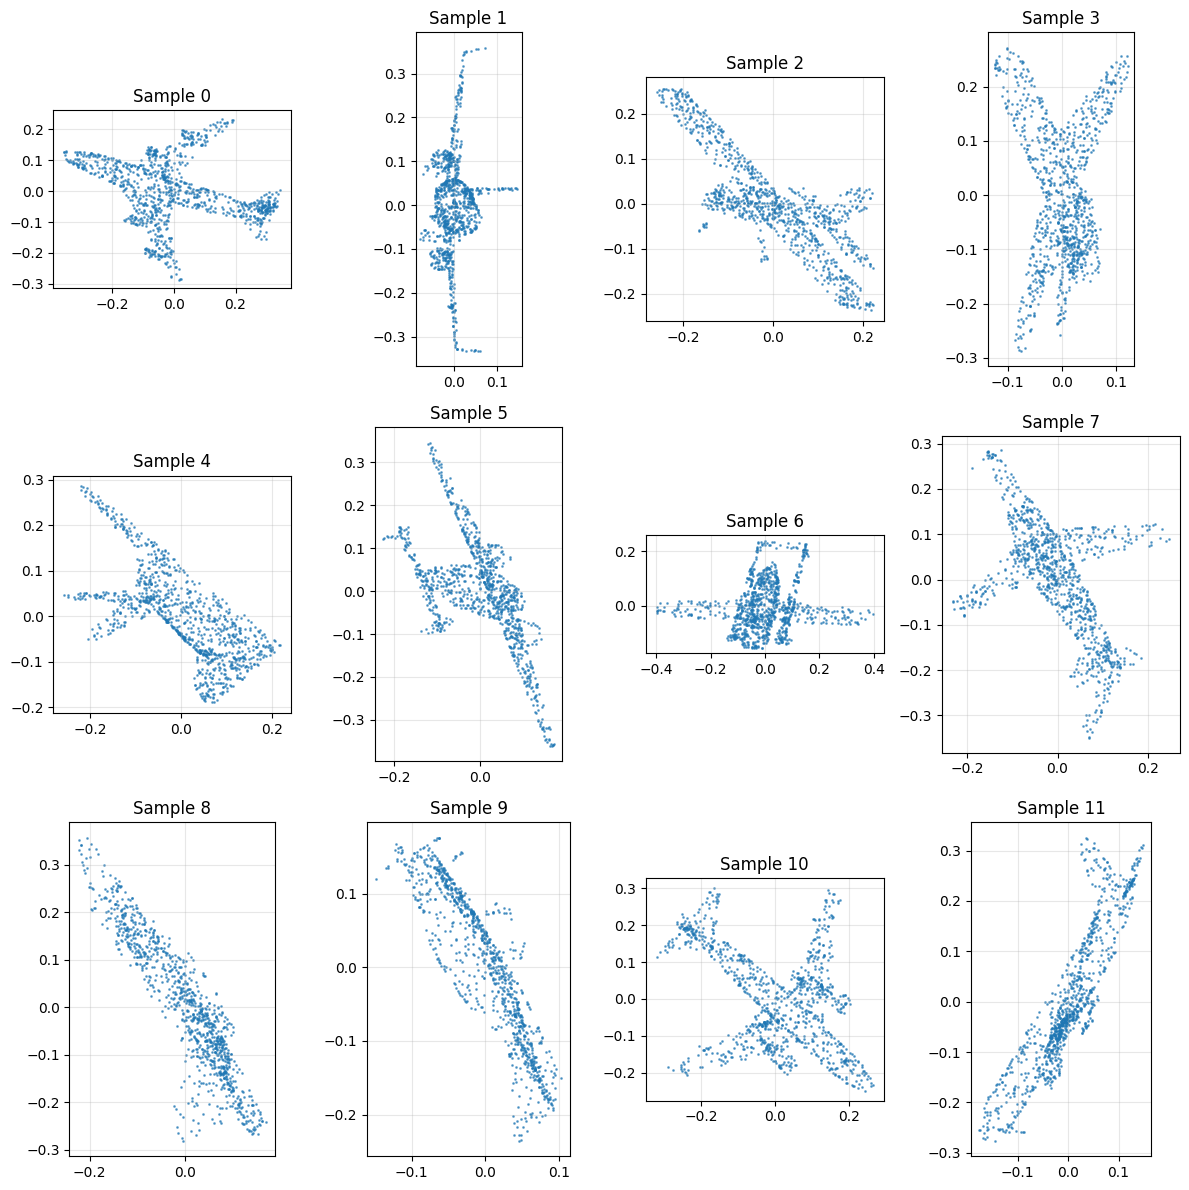

In [15]:
import matplotlib.pyplot as plt

# Fetch a batch
batch_size = 12
samples = [base_dataset[i] for i in range(batch_size)]

# Plot
fig, axes = plt.subplots(3, 4, figsize=(12, 12))
axes = axes.flatten()

for idx, (pc, label, R) in enumerate(samples):
    ax = axes[idx]
    pc_np = pc.cpu().numpy()
    ax.scatter(pc_np[:, 0], pc_np[:, 1], s=1, alpha=0.6)
    ax.set_title(f'Sample {idx}')
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('pointcloud_samples.png', dpi=150, bbox_inches='tight')
plt.show()

In [16]:
print("=" * 60)
print("EVALUATION")
print("=" * 60)

model.eval()
test_dataset = ShapeNetPointCloudDataset(processed_dir, num_points=NUM_POINTS, max_samples=None)

# Stability: same shape, different rotations (Eq. 1)
print("\nComputing stability (same shape, different rotations)...")
sample_stabilities = []
for i in range(min(10, len(test_dataset))):
    pc, _, _ = test_dataset[i]
    pc = pc.to(device)
    stability = compute_stability(model, pc, num_rotations=10)
    sample_stabilities.append(stability)
    
print(f"  Stability: {np.mean(sample_stabilities):.2f} +/- {np.std(sample_stabilities):.2f} degrees")

# Consistency: different shapes, same class (Eq. 2)
print("\nComputing consistency (different shapes, same class)...")
consistency = compute_consistency(model, test_dataset, num_samples=min(100, len(test_dataset)))
print(f"  Consistency: {consistency:.2f} degrees")

# Verify equivariance: f(PR) = f(P)R
print("\nTesting equivariance on trained model...")
x = torch.randn(2, NUM_POINTS, 3).to(device)
R_test = random_rotation_matrix(1)[0].to(device)
x_rot = x @ R_test

with torch.no_grad():
    R_final1, R_hyp1, _ = model(x)
    R_final2, R_hyp2, _ = model(x_rot)
    
    # h(PR) vs h(P)R
    R_hyp1_rot = R_hyp1 @ R_test
    print(f"  h(PR) vs h(P)R error: {(R_hyp2 - R_hyp1_rot).abs().max().item():.6f}")
    
    # f(PR) vs f(P)R
    R_final1_rot = R_final1 @ R_test
    print(f"  f(PR) vs f(P)R error: {(R_final2 - R_final1_rot).abs().max().item():.6f}")
    
    # Canonical PC consistency
    canon1 = x @ R_final1.transpose(-1, -2)
    canon2 = x_rot @ R_final2.transpose(-1, -2)
    print(f"  Canonical PC difference: {(canon2 - canon1).abs().max().item():.6f}")

print("\n" + "=" * 60)
print("EVALUATION COMPLETE")
print("=" * 60)

EVALUATION

Computing stability (same shape, different rotations)...
  Stability: 57.78 +/- 16.15 degrees

Computing consistency (different shapes, same class)...
  Consistency: 76.84 degrees

Testing equivariance on trained model...
  h(PR) vs h(P)R error: 0.000694
  f(PR) vs f(P)R error: 0.000824
  Canonical PC difference: 0.003006

EVALUATION COMPLETE


In [17]:
# ══════════════════════════════════════════════════════════════════════════
#  EQUIVARIANCE / INVARIANCE TESTS  –  no einsum, plain matmul
# ══════════════════════════════════════════════════════════════════════════

import torch

def rot_vn_4d(x, R):
    # x: [B, C, 3, N]  – rotate the 3-dim by R [3,3]
    # move 3 to last dim, matmul R.T, move back
    # [B,C,3,N] -> [B,C,N,3] @ R.T -> [B,C,N,3] -> [B,C,3,N]
    return (x.permute(0, 1, 3, 2) @ R).permute(0, 1, 3, 2)

def rot_vn_3d(x, R):
    # x: [B, C, 3]  – rotate the last dim by R [3,3]
    return x @ R

def rot_pc(x, R):
    # x: [B, N, 3]  – standard point cloud rotation
    return x @ R

def check(label, got, want, tol=1e-4, tag="EQUIVARIANT"):
    err = (got - want).abs().max().item()
    ok  = "✓" if err < tol else "✗"
    print(f"  {ok} {label:<32s}  max|delta| = {err:.2e}  [{tag}]")

# ── setup ──────────────────────────────────────────────────────────────────
device = next(model.parameters()).device
model.eval()

pc, _, _ = base_dataset[1]
pc = pc[:NUM_POINTS].unsqueeze(0).to(device)   # [1, N, 3]

R      = random_rotation_matrix(1)[0].to(device)  # [3, 3]
pc_rot = rot_pc(pc, R)                             # P.R  [1, N, 3]

B, N = pc.shape[0], pc.shape[1]

print("=" * 68)
print("  EQUIVARIANCE / INVARIANCE TESTS")
print("=" * 68)

with torch.no_grad():

    # ── 1. VNLinear ────────────────────────────────────────────────────────
    # input : [B, C_in, 3, N]    output: [B, C_out, 3, N]
    # test  : f(x.R) == f(x).R  on the 3-dim
    C_in, C_out = 8, 16
    vn_lin = VNLinear(C_in, C_out).to(device).eval()

    x_P  = torch.randn(B, C_in, 3, N, device=device)
    x_PR = rot_vn_4d(x_P, R)          # rotate the input

    out_P  = vn_lin(x_P)              # f(P)
    out_PR = vn_lin(x_PR)             # f(P.R)
    want   = rot_vn_4d(out_P, R)      # f(P).R  <- what equivariance demands
    check("VNLinear", out_PR, want)

    # ── 2. VNLeakyReLU ────────────────────────────────────────────────────
    # input : [B, C, 3, N]    output: [B, C, 3, N]
    C = 16
    vn_relu = VNLeakyReLU(C).to(device).eval()

    x_P  = torch.randn(B, C, 3, N, device=device)
    x_PR = rot_vn_4d(x_P, R)

    out_P  = vn_relu(x_P)
    out_PR = vn_relu(x_PR)
    want   = rot_vn_4d(out_P, R)
    check("VNLeakyReLU", out_PR, want)

    # ── 3. VNBatchNorm ────────────────────────────────────────────────────
    # input : [B, C, 3, N]    output: [B, C, 3, N]
    # BN only rescales vector norms (rotation-invariant scalars),
    # so direction still rotates freely -> equivariant
    C = 16
    vn_bn = VNBatchNorm(C, dim=4).to(device)
    vn_bn.train()
    vn_bn(torch.randn(4, C, 3, N, device=device))   # warm-up running stats
    vn_bn.eval()

    x_P  = torch.randn(B, C, 3, N, device=device)
    x_PR = rot_vn_4d(x_P, R)

    out_P  = vn_bn(x_P)
    out_PR = vn_bn(x_PR)
    want   = rot_vn_4d(out_P, R)
    check("VNBatchNorm", out_PR, want)

    # ── 4. VNLinearLeakyReLU ──────────────────────────────────────────────
    # input : [B, C_in, 3, N]    output: [B, C_out, 3, N]
    C_in, C_out = 8, 16
    vn_llr = VNLinearLeakyReLU(C_in, C_out, dim=4).to(device)
    vn_llr.train()
    vn_llr(torch.randn(4, C_in, 3, N, device=device))  # warm-up BN
    vn_llr.eval()

    x_P  = torch.randn(B, C_in, 3, N, device=device)
    x_PR = rot_vn_4d(x_P, R)

    out_P  = vn_llr(x_P)
    out_PR = vn_llr(x_PR)
    want   = rot_vn_4d(out_P, R)
    check("VNLinearLeakyReLU", out_PR, want)

    # ── 5. VNMaxPool ──────────────────────────────────────────────────────
    # input : [B, C, 3, N]    output: [B, C, 3]   (N pooled away)
    # argmax of dot-products is rotation-invariant -> selected vector rotates
    C = 16
    vn_pool = VNMaxPool(C).to(device).eval()

    x_P  = torch.randn(B, C, 3, N, device=device)
    x_PR = rot_vn_4d(x_P, R)

    out_P  = vn_pool(x_P)             # [B, C, 3]
    out_PR = vn_pool(x_PR)            # [B, C, 3]
    want   = rot_vn_3d(out_P, R)      # rotate 3-dim without N trailing dim
    check("VNMaxPool", out_PR, want)

    # ── 6. VNEncoder ──────────────────────────────────────────────────────
    # input : [B, N, 3] point cloud    output: [B, C, 3, N] equiv features
    # phi(P.R) = phi(P).R
    enc = model.hypothesizer.encoder

    feat_P  = enc(pc)                  # phi(P)
    feat_PR = enc(pc_rot)              # phi(P.R)
    want    = rot_vn_4d(feat_P, R)    # phi(P).R
    check("VNEncoder", feat_PR, want)

    # ── 7. VNInvariantLayer ───────────────────────────────────────────────
    # input : [B, C, 3, N]    output: [B, 3, 3, N]  (still equivariant frame V)
    # V(P.R) = V(P).R  (used later to cancel: phi(P.R) @ V(P.R)^T = phi(P) @ V(P)^T)
    inv_layer = model.hypothesizer.inv_layer

    V_P  = inv_layer(feat_P)           # [B, 3, 3, N]
    V_PR = inv_layer(feat_PR)
    want = rot_vn_4d(V_P, R)
    check("VNInvariantLayer", V_PR, want)

    # ── 8. RotationPredictor ──────────────────────────────────────────────
    # input : [B, C, 3, N] equiv features    output: [B, 3, 3] rotation matrix
    # psi(phi(P.R)) = psi(phi(P)) @ R   (right-multiply for SO(3) matrices)
    rot_pred = model.hypothesizer.rotation_predictor
    R_hyp_P  = rot_pred(feat_P)        # psi(phi(P))    [B,3,3]
    R_hyp_PR = rot_pred(feat_PR)       # psi(phi(P.R))  [B,3,3]
    want     = R_hyp_P @ R             # psi(phi(P)) @ R
    check("RotationPredictor", R_hyp_PR, want)

    # ── 9. OrientationHypothesizer ────────────────────────────────────────
    # input : [B, N, 3] point cloud    output: R_hyp [B,3,3]
    # h(P.R) = h(P) @ R
    hyp = model.hypothesizer

    R_h_P,  phi_P,  V_P2  = hyp(pc)
    R_h_PR, phi_PR, V_PR2 = hyp(pc_rot)
    want = R_h_P @ R
    check("OrientationHypothesizer", R_h_PR, want)

    # ── 10. InvariantFeatureExtractor ─────────────────────────────────────
    # phi(P.R) @ V(P.R)^T = phi(P).R @ R^T.V(P)^T = phi(P) @ V(P)^T
    # -> same output regardless of rotation  (INVARIANT)
    # input : phi [B,C,3,N] and V [B,3,3,N]   output: [B, N, C*3]
    inv_ext = model.residual_predictor.inv_feat_extractor

    inv_P  = inv_ext(phi_P,  V_P2)    # phi(P) @ V(P)^T
    inv_PR = inv_ext(phi_PR, V_PR2)   # phi(P.R) @ V(P.R)^T  = same
    check("InvariantFeatureExtractor", inv_PR, inv_P, tag="INVARIANT")

    # ── 11. ResidualPredictor ─────────────────────────────────────────────
    # input : canon_pc [B,N,3] (invariant) + phi,V (for invariant features)
    # output: [B,3,3] rotation – same regardless of input rotation (INVARIANT)
    res_pred = model.residual_predictor

    canon_P  = pc      @ R_h_P.transpose(-1, -2)   # P h(P)^T    [B,N,3]
    canon_PR = pc_rot  @ R_h_PR.transpose(-1, -2)  # PR h(PR)^T  = same

    R_res_P  = res_pred(canon_P,  phi_P,  V_P2)
    R_res_PR = res_pred(canon_PR, phi_PR, V_PR2)
    check("ResidualPredictor", R_res_PR, R_res_P, tag="INVARIANT")

    # ── 12. CHOIR full model ──────────────────────────────────────────────
    # f(P.R) = f(P) @ R   end-to-end equivariance (Eq. 6)
    R_f_P,  _, _ = model(pc)
    R_f_PR, _, _ = model(pc_rot)
    want = R_f_P @ R
    check("CHOIR full model", R_f_PR, want)

    # bonus: canonicalized PC = P @ f(P)^T  should be identical for P and P.R
    canon1 = pc      @ R_f_P.transpose(-1, -2)
    canon2 = pc_rot  @ R_f_PR.transpose(-1, -2)
    check("Canonical PC", canon2, canon1, tag="INVARIANT")

print()
print("  max|delta| < 1e-4  ->  property holds numerically")
print("  EQUIVARIANT: f(P.R) == f(P) @ R")
print("  INVARIANT  : f(P.R) == f(P)  (same output)")
print("=" * 68)

  EQUIVARIANCE / INVARIANCE TESTS
  ✓ VNLinear                          max|delta| = 4.77e-07  [EQUIVARIANT]
  ✓ VNLeakyReLU                       max|delta| = 1.43e-06  [EQUIVARIANT]
  ✓ VNBatchNorm                       max|delta| = 7.15e-07  [EQUIVARIANT]
  ✓ VNLinearLeakyReLU                 max|delta| = 1.07e-06  [EQUIVARIANT]
  ✓ VNMaxPool                         max|delta| = 2.38e-07  [EQUIVARIANT]
  ✓ VNEncoder                         max|delta| = 2.24e-07  [EQUIVARIANT]
  ✓ VNInvariantLayer                  max|delta| = 1.16e-07  [EQUIVARIANT]
  ✓ RotationPredictor                 max|delta| = 3.35e-05  [EQUIVARIANT]
  ✓ OrientationHypothesizer           max|delta| = 3.35e-05  [EQUIVARIANT]
  ✓ InvariantFeatureExtractor         max|delta| = 1.12e-08  [INVARIANT]
  ✓ ResidualPredictor                 max|delta| = 4.93e-05  [INVARIANT]
  ✓ CHOIR full model                  max|delta| = 4.86e-05  [EQUIVARIANT]
  ✓ Canonical PC                      max|delta| = 1.57e-05  [INVARIAN

/usr/local/lib/python3.12/dist-packages/torch/functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4322.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
